In [1]:
!pip install PyMPDATA

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [PyMPDATA]


In [2]:
import PyMPDATA
print(PyMPDATA.__file__)

/usr/local/lib/python3.13/dist-packages/PyMPDATA/__init__.py


In [7]:
import numpy as np
import matplotlib.pyplot as plt

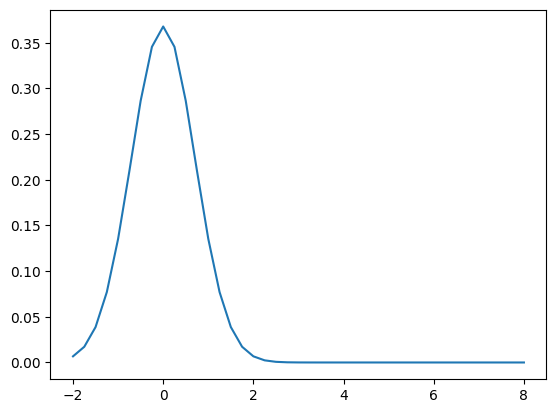

In [23]:
x = np.linspace(-2,8,41)
psi = np.exp((-x*x)-1)

plt.plot(x,psi)
plt.show()



In [24]:
from PyMPDATA import ScalarField, VectorField, Options, Stepper, Solver, boundary_conditions

In [25]:
halo:int
boundry_conditions:tuple


In [29]:
common={
    'halo':(options:=Options(nonoscillatory=True)).n_halo,
    'boundary_conditions':(boundary_conditions.Periodic(),),
}
advector=VectorField(**common,data=(np.full(x.size+1,1/4),))
advectee=ScalarField(**common,data=psi)
solver=Solver(advectee=advectee,advector=advector,stepper=Stepper(n_dims=1,options=options))
solver.advance(n_steps=100)

9183.44

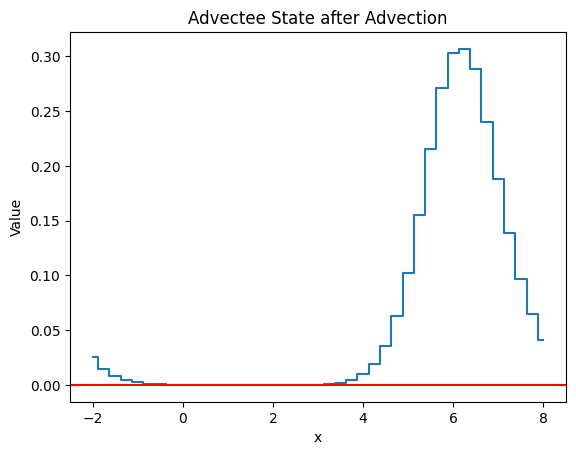

In [30]:
plt.step(x, advectee.get(), where='mid')
plt.axhline(y=0, color='r', linestyle='-')
plt.title('Advectee State after Advection')
plt.xlabel('x')
plt.ylabel('Value')
plt.show()